# 10장. 분류 분석으로 주문 취소 여부 예측하기

이 노트북은 완료 주문과 취소 주문만 사용해 `is_cancelled`를 예측하는 이진 분류 실습입니다.

## 학습 목표

- `completed=0`, `cancelled=1`로 타깃 범위를 명확하게 정의합니다.
- `refunded`와 기타 상태를 이진 분류 대상에서 제외합니다.
- 병합의 키 관계, 행 수, 미매칭을 검증합니다.
- train, validation, test를 분리합니다.
- Dummy 기준 모델, Logistic Regression, Random Forest를 비교합니다.
- validation에서 모델과 임계값을 선택하고 test는 최종 평가에 한 번만 사용합니다.
- 예측 결과에서 고객명 등 불필요한 개인정보를 제외합니다.


## 1. 프로젝트 루트와 실행 환경 설정

전처리 파일이 없다면 프로젝트 루트에서 먼저 다음 명령을 실행하세요.

```bash
python scripts/preprocess_data.py
```


In [1]:
from pathlib import Path
import sys

import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / 'requirements.txt').exists() and (candidate / 'scripts').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트 폴더를 찾을 수 없습니다.')


PROJECT_ROOT = find_project_root(Path.cwd())
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('Python 실행 파일:', sys.executable)
print('프로젝트 루트:', PROJECT_ROOT)
print('전처리 데이터 폴더:', PROCESSED_DIR)
print('보고서 폴더:', REPORT_DIR)


Python 실행 파일: d:\dev\llm-data-analysis-course\.venv\Scripts\python.exe
프로젝트 루트: D:\dev\llm-data-analysis-course
전처리 데이터 폴더: D:\dev\llm-data-analysis-course\data\processed
보고서 폴더: D:\dev\llm-data-analysis-course\reports


## 2. 전처리 데이터 확인과 불러오기

이 장에서는 `customers_clean.csv`, `orders_clean.csv`, `order_items_clean.csv`를 사용합니다.


In [2]:
required_files = [
    PROCESSED_DIR / 'customers_clean.csv',
    PROCESSED_DIR / 'orders_clean.csv',
    PROCESSED_DIR / 'order_items_clean.csv',
]

missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        '전처리 파일이 없습니다: '
        + ', '.join(str(path) for path in missing_files)
        + '. 먼저 python scripts/preprocess_data.py를 실행하세요.'
    )

customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

print('customers:', customers.shape, customers.columns.tolist())
print('orders:', orders.shape, orders.columns.tolist())
print('order_items:', order_items.shape, order_items.columns.tolist())


customers: (150, 6) ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
orders: (300, 7) ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status', 'order_month', 'order_dayofweek']
order_items: (764, 6) ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price', 'line_total']


## 3. 주문 상태와 타깃 범위 확인

이번 실습은 완료 주문과 취소 주문만 비교합니다.

- `completed` → 0
- `cancelled` → 1
- `refunded`와 기타 상태 → 학습 대상에서 제외


In [3]:
status_summary = (
    orders['order_status']
    .value_counts(dropna=False)
    .rename_axis('order_status')
    .reset_index(name='order_count')
)
status_summary


,order_status,order_count
0,completed,184
1,cancelled,64
2,refunded,52


## 4. 분류 데이터와 병합 검증표 생성

공통 함수는 주문 특징 집계, 안전한 병합, 시간 순서 점검, 타깃 생성까지 수행합니다.


In [4]:
from src.classification import (
    build_classification_dataset,
    target_distribution,
)

try:
    (
        model_data,
        numeric_features,
        categorical_features,
        merge_checks,
        data_quality_checks,
    ) = build_classification_dataset(
        customers=customers,
        orders=orders,
        order_items=order_items,
    )
    print('원본 데이터로 분류 데이터 생성 성공')
except ValueError as error:
    print('원본 데이터로 분류 데이터 생성 실패')
    print('ValueError:', error)

원본 데이터로 분류 데이터 생성 실패
ValueError: signup_date가 order_date보다 늦은 주문이 있습니다: 45건


In [5]:
# from src.classification import (
#     build_classification_dataset,
#     target_distribution,
# )

# (
#     model_data,
#     numeric_features,
#     categorical_features,
#     merge_checks,
#     data_quality_checks,
# ) = build_classification_dataset(
#     customers=customers,
#     orders=orders,
#     order_items=order_items,
# )

# target_dist = target_distribution(model_data)

# print('모델링 데이터:', model_data.shape)
# print('숫자형 feature:', numeric_features)
# print('범주형 feature:', categorical_features)
# display(target_dist)
# display(merge_checks)
# display(data_quality_checks)


에러남!


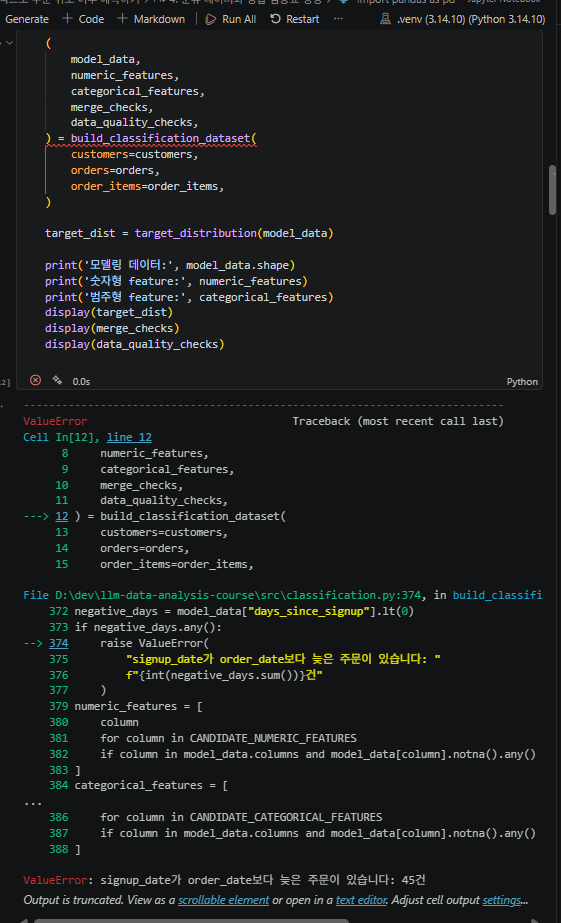

### ????? 이상 데이터 존재????



가능한 원인 4가지:

- 잘못된 데이터 입력
    - 예: 회원 가입일을 주문일보다 늦게 입력한 경우
- 날짜 포맷/타임존 문제
    - 문자열 처리 과정에서 날짜가 제대로 파싱되지 않았을 수 있음
- 병합 키 오류
    - customer_id가 잘못 연결됐을 가능성
- 테스트 데이터/샘플 데이터 문제
    - 일부 더미 데이터가 실제 비즈니스 규칙과 맞지 않을 수 있음
### [이상 주문 확인]

```python
import pandas as pd

# customers + orders 조인
merged = orders.merge(
    customers[["customer_id", "signup_date"]],
    on="customer_id",
    how="left"
).copy()

merged["order_date"] = pd.to_datetime(merged["order_date"], errors="coerce")
merged["signup_date"] = pd.to_datetime(merged["signup_date"], errors="coerce")

merged["days_since_signup"] = (
    merged["order_date"] - merged["signup_date"]
).dt.days

bad = merged[merged["days_since_signup"] < 0].copy()

print("이상 주문 수:", len(bad))
display(bad.head(20))
```


---


### [고객별 이상 건수]

```python
# 고객별 이상 건수
customer_issue = (
    bad.groupby("customer_id")
       .size()
       .reset_index(name="bad_order_count")
       .sort_values("bad_order_count", ascending=False)
)

display(customer_issue.head(20))
```


---


### [주문 상태별 이상 건수]
```python
# 주문 상태별 이상 건수
status_issue = (
    bad["order_status"]
       .value_counts()
       .rename_axis("order_status")
       .reset_index(name="count")
)

display(status_issue)
```

---


### [date 변환 검증]


```python
# date 변환 검증
print("signup_date 변환 실패 수:", merged["signup_date"].isna().sum())
print("order_date 변환 실패 수:", merged["order_date"].isna().sum())
```




- 특정 customer_id만 계속 문제를 일으키는가?
- cancelled 주문만 이상하게 많나?
- signup_date가 어떤 형식으로 들어왔는가?
- 어떤 row는 signup_date가 결측이 아니라 잘못 입력됐는가?



In [6]:
import pandas as pd

# 1) 가입일과 주문일 비교
joined = (
    orders.merge(
        customers[["customer_id", "signup_date"]],
        on="customer_id",
        how="left"
    )
    .copy()
)

joined["order_date"] = pd.to_datetime(joined["order_date"], errors="coerce")
joined["signup_date"] = pd.to_datetime(joined["signup_date"], errors="coerce")

joined["days_since_signup"] = (
    joined["order_date"] - joined["signup_date"]
).dt.days

invalid_orders = joined.loc[joined["days_since_signup"] < 0, [
    "customer_id",
    "order_id",
    "order_status",
    "order_date",
    "signup_date",
    "days_since_signup"
]].copy()

print(f"문제 주문 수: {len(invalid_orders)}")
display(invalid_orders.head(20))


문제 주문 수: 56


,customer_id,order_id,order_status,order_date,signup_date,days_since_signup
6,120,7,refunded,2026-02-04,2026-04-23,-78
10,47,11,completed,2026-01-24,2026-02-18,-25
12,117,13,completed,2026-08-09,2026-08-31,-22
18,6,19,completed,2026-02-01,2026-09-03,-214
24,148,25,cancelled,2025-11-12,2026-08-22,-283
31,111,32,cancelled,2026-05-11,2026-07-26,-76
48,104,49,completed,2025-10-17,2026-09-02,-320
52,117,53,completed,2025-12-17,2026-08-31,-257
54,50,55,completed,2026-03-13,2026-06-26,-105
58,50,59,completed,2026-02-08,2026-06-26,-138


In [7]:
#제외할 order_id

bad_order_ids = invalid_orders["order_id"].dropna().unique()
print("제외할 order_id 개수:", len(bad_order_ids))
print(bad_order_ids[:10])

제외할 order_id 개수: 56
[ 7 11 13 19 25 32 49 53 55 59]


In [8]:
#정상 주문만 남기고 다시 데이터 생성

orders_clean = orders.loc[~orders["order_id"].isin(bad_order_ids)].copy()

(
    model_data,
    numeric_features,
    categorical_features,
    merge_checks,
    data_quality_checks,
) = build_classification_dataset(
    customers=customers,
    orders=orders_clean,
    order_items=order_items,
)

target_dist = target_distribution(model_data)

print('모델링 데이터:', model_data.shape)
print('숫자형 feature:', numeric_features)
print('범주형 feature:', categorical_features)
display(target_dist)
display(merge_checks)
display(data_quality_checks)

모델링 데이터: (203, 16)
숫자형 feature: ['age', 'item_count', 'total_quantity', 'order_amount', 'order_month', 'order_dayofweek', 'days_since_signup']
범주형 feature: ['gender', 'city', 'payment_method']


,is_cancelled,class_label,count,ratio
0,0,completed,149,0.734
1,1,cancelled,54,0.266


,merge,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → order_item_features,203,203,True,0,PASS
1,customer_id → customers,203,203,True,0,PASS


,check_item,count
0,binary_target_rows,203
1,completed_rows,149
2,cancelled_rows,54
3,excluded_status_rows,41
4,line_total_mismatch,0
5,negative_days_since_signup,0
6,missing_order_item_features,0
7,missing_customer_match,0
8,status_scope:completed,149
9,status_scope:cancelled,54


## 5. 데이터 누수 확인

`order_status`와 `is_cancelled`는 입력 feature에 포함되면 안 됩니다.


In [9]:
features = numeric_features + categorical_features
leakage_columns = {'order_status', 'is_cancelled'}
leakage_found = sorted(leakage_columns.intersection(features))

if leakage_found:
    raise ValueError(f'데이터 누수 위험 컬럼이 포함되었습니다: {leakage_found}')

print('사용 feature:', features)
print('데이터 누수 컬럼 없음')


사용 feature: ['age', 'item_count', 'total_quantity', 'order_amount', 'order_month', 'order_dayofweek', 'days_since_signup', 'gender', 'city', 'payment_method']
데이터 누수 컬럼 없음


## 6. train, validation, test 분리

모델과 임계값은 validation에서 선택하고, test는 최종 평가에 한 번만 사용합니다.


In [10]:
from src.classification import (
    split_train_validation_test,
    build_split_summary,
)

(
    X_train,
    X_valid,
    X_test,
    y_train,
    y_valid,
    y_test,
    features,
) = split_train_validation_test(
    model_data=model_data,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    random_state=42,
)

split_summary = build_split_summary(y_train, y_valid, y_test)

print('X_train:', X_train.shape)
print('X_valid:', X_valid.shape)
print('X_test:', X_test.shape)
display(split_summary)


X_train: (121, 10)
X_valid: (41, 10)
X_test: (41, 10)


,split,is_cancelled,class_label,count,ratio
0,train,0,completed,89,0.7355
1,train,1,cancelled,32,0.2645
2,validation,0,completed,30,0.7317
3,validation,1,cancelled,11,0.2683
4,test,0,completed,30,0.7317
5,test,1,cancelled,11,0.2683


## 7. 기준 모델과 학습 모델 비교

가장 많은 클래스만 예측하는 Dummy 모델을 기준으로 Logistic Regression과 Random Forest의 validation 성능을 비교합니다.


In [11]:
from src.classification import train_and_compare_on_validation

(
    models,
    validation_comparison,
    validation_predictions,
    validation_probabilities,
) = train_and_compare_on_validation(
    X_train=X_train,
    X_valid=X_valid,
    y_train=y_train,
    y_valid=y_valid,
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    random_state=42,
)

validation_comparison


,model,evaluation_split,accuracy,precision,recall,f1
0,Logistic Regression,validation,0.634146,0.409091,0.818182,0.545455
1,Random Forest,validation,0.707317,0.428571,0.272727,0.333333
2,Dummy Most Frequent,validation,0.731707,0.000000,0.000000,0.000000


## 8. validation에서 모델과 임계값 선택

Dummy 모델은 기준선이므로 실제 선택 후보에서는 제외합니다. validation의 f1-score를 우선하고 recall과 precision을 함께 확인합니다.


In [12]:
from src.classification import threshold_metrics, choose_threshold

non_dummy_comparison = validation_comparison[
    validation_comparison['model'] != 'Dummy Most Frequent'
]

selected_model_name = str(non_dummy_comparison.iloc[0]['model'])
selected_model = models[selected_model_name]
validation_proba = validation_probabilities[selected_model_name]

threshold_df = threshold_metrics(y_valid, validation_proba)
selected_threshold = choose_threshold(threshold_df)

print('선택 모델:', selected_model_name)
print('선택 임계값:', selected_threshold)
display(threshold_df.sort_values(['f1', 'recall'], ascending=False).head(10))


선택 모델: Logistic Regression
선택 임계값: 0.6


,threshold,accuracy,precision,recall,f1
8,0.60,0.804878,0.666667,0.545455,0.600000
6,0.50,0.634146,0.409091,0.818182,0.545455
7,0.55,0.707317,0.466667,0.636364,0.538462
5,0.45,0.585366,0.375000,0.818182,0.514286
4,0.40,0.560976,0.360000,0.818182,0.500000
2,0.30,0.487805,0.333333,0.909091,0.487805
3,0.35,0.536585,0.346154,0.818182,0.486486
9,0.65,0.780488,0.666667,0.363636,0.470588
1,0.25,0.365854,0.297297,1.000000,0.458333
0,0.20,0.341463,0.289474,1.000000,0.448980


## 9. test 데이터 최종 평가

이제 선택이 끝났으므로 test 데이터에서 최종 성능을 한 번 확인합니다.


In [13]:
from src.classification import (
    final_test_evaluation,
    confusion_matrix_dataframe,
    classification_report_dataframe,
)

y_pred_test, y_proba_test, test_metrics = final_test_evaluation(
    selected_model,
    X_test,
    y_test,
    threshold=selected_threshold,
)

confusion_df = confusion_matrix_dataframe(y_test, y_pred_test)
classification_report_df = classification_report_dataframe(y_test, y_pred_test)

display(test_metrics)
display(confusion_df)
display(classification_report_df)


,evaluation_split,threshold,selection_status,accuracy,precision,recall,f1
0,test,0.6,frozen_before_test,0.682927,0.4,0.363636,0.380952


,pred_completed,pred_cancelled
actual_completed,24,6
actual_cancelled,7,4


,label,precision,recall,f1-score,support
0,completed,0.774194,0.800000,0.786885,30.000000
1,cancelled,0.400000,0.363636,0.380952,11.000000
2,accuracy,0.682927,0.682927,0.682927,0.682927
3,macro avg,0.587097,0.581818,0.583919,41.000000
4,weighted avg,0.673800,0.682927,0.677976,41.000000


혼동행렬은 다음처럼 읽습니다.

| 구분 | 의미 |
|---|---|
| True Negative | 실제 완료 주문을 완료로 예측 |
| False Positive | 실제 완료 주문을 취소로 잘못 예측 |
| False Negative | 실제 취소 주문을 완료로 잘못 예측 |
| True Positive | 실제 취소 주문을 취소로 예측 |


## 10. 개인정보를 제외한 예측 결과 생성

고객명, 이메일, 주소 같은 불필요한 식별정보는 결과 파일에 저장하지 않습니다.


In [14]:
from src.classification import create_prediction_result

prediction_result = create_prediction_result(
    source_index=X_test.index,
    y_test=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=selected_model_name,
    threshold=selected_threshold,
)

prediction_result.head()


,record_id,source_index,actual_is_cancelled,predicted_is_cancelled,cancel_probability,model,threshold
0,test_0001,79,0,0,0.455600,Logistic Regression,0.6
1,test_0002,20,0,0,0.455474,Logistic Regression,0.6
2,test_0003,104,0,0,0.406504,Logistic Regression,0.6
3,test_0004,119,1,1,0.917927,Logistic Regression,0.6
4,test_0005,29,0,0,0.418720,Logistic Regression,0.6


## 11. LLM 코드 검토 체크리스트


In [15]:
from src.classification import build_classification_checklist

classification_checklist = build_classification_checklist()
classification_checklist


,check_item,status
0,completed와 cancelled만 사용해 이진 타깃을 만들었는가?,□
1,refunded 등 다른 상태를 0 클래스에 섞지 않았는가?,□
2,예측 시점과 feature 가용성 가정을 설명할 수 있는가?,□
3,line_total = quantity × unit_price를 검증했는가?,□
4,병합에 validate를 사용하고 미매칭 0건을 확인했는가?,□
5,"order_status, target, ID, 사후 정보를 feature에서 제외했는가?",□
6,"train, validation, test를 분리했는가?",□
7,모델과 threshold는 validation에서 선택했는가?,□
8,모델과 threshold를 고정한 뒤 test를 한 번만 사용했는가?,□
9,Dummy 기준 모델과 비교했는가?,□


## 12. 전체 파이프라인 실행과 산출물 저장

위 과정을 한 번에 다시 실행해 CSV와 Markdown 보고서를 생성합니다.


In [16]:
from src.classification import run_classification_analysis

# 전체 파이프라인은 data/processed의 CSV를 다시 읽습니다.
# 위에서 제외한 56건은 반영되지 않으므로, 원본 데이터 기준 실행 결과를 그대로 기록합니다.
try:
    classification_result = run_classification_analysis(
        processed_dir=PROCESSED_DIR,
        report_dir=REPORT_DIR,
        random_state=42,
    )
    print('선택 모델:', classification_result['selected_model_name'])
    print('선택 임계값:', classification_result['selected_threshold'])
    display(classification_result['test_metrics'])
    for name, path in classification_result['output_paths'].items():
        print(name, path, 'OK' if path.exists() else 'MISSING')
except ValueError as error:
    print('전체 파이프라인 실행 실패 (data/processed 원본 기준)')
    print('ValueError:', error)

전체 파이프라인 실행 실패 (data/processed 원본 기준)
ValueError: signup_date가 order_date보다 늦은 주문이 있습니다: 45건


In [17]:
# from src.classification import run_classification_analysis

# classification_result = run_classification_analysis(
#     processed_dir=PROCESSED_DIR,
#     report_dir=REPORT_DIR,
#     random_state=42,
# )

# print('선택 모델:', classification_result['selected_model_name'])
# print('선택 임계값:', classification_result['selected_threshold'])
# display(classification_result['test_metrics'])

# for name, path in classification_result['output_paths'].items():
#     print(name, path, 'OK' if path.exists() else 'MISSING')


## 13. LLM 검토 프롬프트 예시

```text
온라인 쇼핑몰 주문 취소 분류 코드를 검토해 주세요.

타깃 기준:
- completed=0
- cancelled=1
- refunded와 기타 상태는 제외

검토 항목:
1. order_status와 is_cancelled가 feature에서 제외되었는가?
2. 병합에 validate와 indicator가 사용되었는가?
3. train, validation, test가 분리되었는가?
4. 모델과 임계값은 validation에서 선택했는가?
5. test는 최종 평가에 한 번만 사용했는가?
6. Dummy 기준 모델보다 나은가?
7. accuracy, precision, recall, f1을 함께 확인했는가?
8. 예측 결과에 개인정보가 포함되지 않았는가?
9. 모델 결과를 취소 원인으로 단정하지 않았는가?

필수 수정과 권장 개선을 구분해 설명해 주세요.
```


## 14. 정리

이번 장에서는 완료 주문과 취소 주문을 명확하게 구분하고, 병합 검증, 데이터 누수 방지, train/validation/test 분리, 기준 모델 비교, validation 기반 모델·임계값 선택, 최종 test 평가를 수행했습니다.

다음 장에서는 LLM을 활용해 분석 질문과 프롬프트를 더 구체적으로 만드는 방법으로 이어집니다.


# Chapter 10 답안 양식. 분류 분석으로 주문 취소 여부 예측하기

> 이 내용을 `chapter10.ipynb`의 Markdown 셀로 작성합니다. 실제 실행 결과를 근거로 작성하고, 예측 패턴을 원인처럼 단정하지 않습니다.

## 제출 정보
- 이름:
- GitHub ID:
- 작성일:
- 최종 Notebook URL:

## 1. 분류 문제 정의
- 타깃:
- 0의 의미:
- 1의 의미:
- 제외한 상태:
- 예측 단위:
- 예측 시점:
- 예측 시점에 사용할 수 있는 정보:
- 예측 이후에만 알 수 있어 제외한 정보:

### 나의 해석과 판단
왜 이 타깃 범위와 예측 시점을 사용했는지 작성하세요.

---

## 2. Feature Contract와 Leakage Audit

### 사용한 숫자형 Feature

### 사용한 범주형 Feature

### 금지 Feature

```text
order_status
is_cancelled
order_id
customer_id
product_id
취소 이후 정보
```

### 나의 해석과 판단
파일에 컬럼이 존재하는 것과 예측 시점에 사용할 수 있는 것이 왜 다른지 작성하세요.

---

## 3. 주문 단위 특징과 병합 검증

### 계산 관계 확인

```text
line_total = quantity × unit_price
```

- 계산 불일치 건수:
- 주문 특징 `order_id` 중복 건수:

### 병합 검증

| 병합 | 관계 | 병합 전 행 수 | 병합 후 행 수 | 미매칭 | 판정 |
| --- | --- | ---: | ---: | ---: | --- |
| 주문 ↔ 주문 특징 | one_to_one | | | | |
| 주문 ↔ 고객 | many_to_one | | | | |

### 결과 관찰

### 나의 해석과 판단
미매칭을 원인 확인 없이 0으로 채우면 안 되는 이유를 작성하세요.

---

## 4. 클래스 비율

| 클래스 | 의미 | 개수 | 비율 |
| ---: | --- | ---: | ---: |
| 0 | completed | | |
| 1 | cancelled | | |

![클래스 비율](images/step02_class_ratio.png)

### 결과 관찰

### 나의 해석과 판단
클래스 불균형이 accuracy 해석에 어떤 영향을 주는지 작성하세요.

---

## 5. Dummy Baseline과 Validation 모델 비교

| 모델 | Accuracy | Precision | Recall | F1 |
| --- | ---: | ---: | ---: | ---: |
| Dummy Most Frequent | | | | |
| Logistic Regression | | | | |
| Random Forest | | | | |

![Baseline 비교](images/step03_baseline.png)

- Validation에서 선택한 모델:

### 결과 관찰

### 나의 해석과 판단
선택한 모델이 Dummy baseline보다 어떤 점에서 나아졌는지 작성하세요.

### 한계와 추가 확인 사항

---

## 6. Train / Validation / Test 역할

| Split | 역할 | 클래스 0 건수 | 클래스 1 건수 |
| --- | --- | ---: | ---: |
| Train | 모델 학습 | | |
| Validation | 모델·Threshold 선택 | | |
| Test | 선택 이후 최종 평가 | | |

### 나의 해석과 판단
왜 Test를 모델 또는 Threshold 선택에 사용하면 안 되는지 작성하세요.

### 교육용 random split의 한계
실제 미래 주문 예측 운영 전에 추가해야 할 평가를 작성하세요.

---

## 7. Validation 성능과 우선 지표

- Accuracy:
- Precision:
- Recall:
- F1:

### 내가 가장 중요하게 본 지표

### 그 이유

> 실제 FP/FN 비용 정보가 없다면 가정임을 명시하세요.

---

## 8. Threshold 비교

| Threshold | Precision | Recall | F1 | 예상 특징 |
| ---: | ---: | ---: | ---: | --- |
| | | | | |
| | | | | |
| | | | | |

![Threshold 비교](images/step05_threshold.png)

### 내가 선택한 Threshold

### 선택 이유

### 나의 해석과 판단
Threshold를 Final Test가 아니라 Validation에서 정해야 하는 이유를 작성하세요.

---

## 9. FP/FN 해석

- FP 의미:
- FN 의미:
- 현재 목적에서 더 부담스러울 수 있는 오류:
- 그 판단에 추가로 필요한 업무 정보:

![Confusion Matrix](images/step06_confusion_matrix.png)

### 업무·분석적 의미

### 한계와 추가 확인 사항

---

## 10. Final Test

- 고정한 모델:
- 고정한 Threshold:
- Accuracy:
- Precision:
- Recall:
- F1:
- Validation 대비 변화:

### 결과 관찰

### 나의 해석과 판단
Final Test 결과를 보고 모델의 일반화 가능성을 어떻게 판단했는지 작성하세요.

### 선택 보호 확인
- [ ] Test 결과를 보기 전에 모델을 고정했습니다.
- [ ] Test 결과를 보기 전에 Threshold를 고정했습니다.
- [ ] Test 결과를 본 뒤 같은 Test를 이용해 선택을 바꾸지 않았습니다.

---

## 11. Internal / Public 결과 구분

### 공개 Prediction 컬럼

```text
record_id
actual_is_cancelled
predicted_is_cancelled
cancel_probability
model
threshold
```

### 공개 결과에 없어야 할 컬럼

```text
source_index
order_id
customer_id
product_id
```

### 결과 관찰

### 나의 해석과 판단
모델 오류 분석용 내부 자료와 공개 결과를 왜 분리해야 하는지 작성하세요.

---

## 12. Validation Evidence

다음 Evidence 중 확인한 항목에 체크합니다.

- [ ] `ch10_target_distribution.csv`
- [ ] `ch10_feature_audit.csv`
- [ ] `ch10_merge_checks.csv`
- [ ] `ch10_data_quality_checks.csv`
- [ ] `ch10_split_summary.csv`
- [ ] `ch10_validation_model_comparison.csv`
- [ ] `ch10_validation_threshold_metrics.csv`
- [ ] `ch10_test_metrics.csv`
- [ ] `ch10_confusion_matrix.csv`
- [ ] `ch10_classification_validation.csv`

### 자동 Validation 결과

### 자동 PASS가 의미하지 않는 것
운영 적합성, 공정성, 시간에 따른 성능 변화 등 자동 검증만으로 판단할 수 없는 내용을 작성하세요.

---

## 13. 최종 사용 판단

- [ ] 참고용 사용 가능
- [ ] 추가 검증 후 사용 가능
- [ ] 현재 사용 보류

### 판단 근거
1.
2.
3.

### 현재 모델의 가장 큰 위험

### 다음 개선 우선순위
1.
2.
3.

### 예측과 인과 구분
현재 모델에서 확인한 것은 어떤 **예측 패턴**이며, 어떤 **원인 주장**은 아직 할 수 없는지 작성하세요.

---

## 최종 체크

- [ ] `completed=0`, `cancelled=1` 타깃 범위를 정의했습니다.
- [ ] `refunded`와 기타 상태를 제외했습니다.
- [ ] 예측 시점과 Feature Contract를 정의했습니다.
- [ ] target, ID, 사후 정보를 feature에서 제외했습니다.
- [ ] `line_total = quantity × unit_price`를 검증했습니다.
- [ ] 주문 단위 특징과 병합 관계를 검증했습니다.
- [ ] 클래스 비율을 확인했습니다.
- [ ] Dummy baseline과 비교했습니다.
- [ ] Train / Validation / Test 역할을 구분했습니다.
- [ ] 모델을 Validation에서 선택했습니다.
- [ ] Threshold를 Validation에서 선택했습니다.
- [ ] Final Test 전에 선택을 고정했습니다.
- [ ] Precision / Recall / F1을 해석했습니다.
- [ ] FP/FN의 의미를 설명했습니다.
- [ ] Public prediction에서 식별자를 제거했습니다.
- [ ] Validation Evidence를 확인했습니다.
- [ ] random split의 한계를 기록했습니다.
- [ ] 예측 패턴을 원인처럼 단정하지 않았습니다.
- [ ] 최종 Notebook URL을 제출합니다.
